# Notebook 10 - Ablation Studies and Final Comparison

**Question:** which parts of the pipeline actually matter, and is the hybrid quantum model better than its classical controls *with statistical evidence*?

This is the closing notebook. It does no training. It only needs the `*_embeddings.npz` files saved by Notebooks 6 and 8 (and Notebook 5 if you saved embeddings there), so it runs on CPU in a few minutes.

## What it produces

| Part | Content |
|---|---|
| 1 | Verification on the test split: ROC, AUC, EER, FAR / FRR at the **validation** EER threshold, TAR@FAR |
| 2 | Identity-level (cluster) bootstrap: confidence intervals for every model |
| 3 | Ablation table: paired differences with 95% CI and a verdict (bottleneck, fine-tuning, head type, entanglement, head on/off) |
| 4 | Identification: Rank-1 / Rank-5 for 1/3/5-shot, mean-template vs max-over-support, paired over episodes |
| 5 | Plots, cross-check against the numbers reported in Notebooks 5-8, saved tables and a written summary |

## Protocol

- Test identities are disjoint from training (Notebook 3).
- Every model is scored on the **same** genuine pairs and the **same** impostor pairs, so all differences are paired.
- Thresholds (FAR / FRR) come from the validation split only; the test split is never used to pick a threshold.
- The bootstrap resamples **identities**, not pairs. Pairs that share an image are not independent, so a pair-level bootstrap gives intervals that are too narrow.

## Limits to keep in mind

- One training seed per variant (Notebook 8). The intervals here capture test-identity sampling, **not** training-seed variance.
- Rank-1 numbers depend on the enrolment draw; Notebook 9 and Part 4 average over many random episodes.

In [1]:
# CELL 1: Imports
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.4 | pandas 3.1.0


In [2]:
# CELL 2: Configuration
SUFFIX = ""             # use "_v2" after you re-run the v2 pipeline (same switch as Notebook 9)
SEED = 42
N_IMPOSTOR = 300_000    # impostor pairs sampled once and shared by all models
N_BOOT = 1000           # identity-level bootstrap replicates
SHOTS = [1, 3, 5]
N_EPISODES = 100        # random enrolment draws per shot (Part 4)
TAR_FARS = [0.01, 0.001]

BASE = Path("..")
OUT = BASE / f"ablation_and_comparison{SUFFIX}"
OUT.mkdir(parents=True, exist_ok=True)
N5 = BASE / f"siamese_metric_learning{SUFFIX}"
N6 = BASE / f"classical_projection_baseline{SUFFIX}"
N7 = BASE / f"quantum_circuit_experiments{SUFFIX}"
H = BASE / f"hybrid_quantum_metric_learning{SUFFIX}"

# name -> (folder, file template, candidate array keys). Missing entries are skipped automatically.
MODELS = {
    "NB5 Siamese 128-D":            (N5, "{split}_embeddings.npz", ["embeddings", "embeddings_128"]),
    "NB6 encoder 128-D":            (N6, "{split}_embeddings.npz", ["embeddings_128"]),
    "NB6 classical 8-D":            (N6, "{split}_embeddings.npz", ["embeddings_8"]),
    "NB8 classical_linear 8-D":     (H, "classical_linear_{split}_embeddings.npz", ["embeddings_final"]),
    "NB8 hybrid_quantum 8-D":       (H, "hybrid_quantum_{split}_embeddings.npz", ["embeddings_final"]),
    "NB8 quantum_product 8-D":      (H, "hybrid_quantum_product_{split}_embeddings.npz", ["embeddings_final"]),
    "NB8 classical_linear pre-head": (H, "classical_linear_{split}_embeddings.npz", ["embeddings_pre_head"]),
    "NB8 hybrid_quantum pre-head":   (H, "hybrid_quantum_{split}_embeddings.npz", ["embeddings_pre_head"]),
    "NB8 quantum_product pre-head":  (H, "hybrid_quantum_product_{split}_embeddings.npz", ["embeddings_pre_head"]),
}

# (ablation, A = treatment, B = control). A - B is reported; pairs with a missing model are skipped.
PAIRS = [
    ("A bottleneck 128-D -> 8-D",      "NB6 classical 8-D",             "NB6 encoder 128-D"),
    ("B encoder: NB5 -> NB6",          "NB6 encoder 128-D",             "NB5 Siamese 128-D"),
    ("C joint fine-tuning (no head)",  "NB8 classical_linear pre-head", "NB6 classical 8-D"),
    ("C joint fine-tuning (no head)",  "NB8 hybrid_quantum pre-head",   "NB6 classical 8-D"),
    ("C joint fine-tuning (no head)",  "NB8 quantum_product pre-head",  "NB6 classical 8-D"),
    ("D head type (quantum vs linear)", "NB8 hybrid_quantum 8-D",       "NB8 classical_linear 8-D"),
    ("D head type (quantum vs linear)", "NB8 quantum_product 8-D",      "NB8 classical_linear 8-D"),
    ("E entanglement",                 "NB8 hybrid_quantum 8-D",        "NB8 quantum_product 8-D"),
    ("F head on vs off (same trunk)",  "NB8 classical_linear 8-D",      "NB8 classical_linear pre-head"),
    ("F head on vs off (same trunk)",  "NB8 hybrid_quantum 8-D",        "NB8 hybrid_quantum pre-head"),
    ("F head on vs off (same trunk)",  "NB8 quantum_product 8-D",       "NB8 quantum_product pre-head"),
    ("G full pipeline vs NB6",         "NB8 hybrid_quantum 8-D",        "NB6 classical 8-D"),
]
print("Output:", OUT, "| bootstrap:", N_BOOT, "| impostor pairs:", N_IMPOSTOR)

Output: ..\ablation_and_comparison | bootstrap: 1000 | impostor pairs: 300000


In [3]:
# CELL 3: Load embeddings (test and validation) and sanity-check them
def l2(x):
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-12, None)

def load(split, verbose):
    emb, ids = {}, None
    for name, (folder, tpl, keys) in MODELS.items():
        path = folder / tpl.format(split=split)
        if not path.exists():
            if verbose: print(f"SKIP  {name:30s} (not found: {path})")
            continue
        z = np.load(path, allow_pickle=True)
        key = next((k for k in keys if k in z.files), None)
        if key is None:
            if verbose: print(f"SKIP  {name:30s} (no key among {keys}; has {z.files})")
            continue
        i = np.asarray(z["identities"])
        if ids is None: ids = i
        elif not np.array_equal(ids, i):
            if verbose: print(f"SKIP  {name:30s} (image order differs from the first model)")
            continue
        emb[name] = l2(z[key].astype(np.float64))
        if verbose: print(f"OK    {name:30s} {emb[name].shape}")
    return emb, ids

TEST, ID_T = load("test", True)
VAL, ID_V = load("validation", False)
assert TEST, "No test embeddings found - check the folders in CELL 2."
print("\nNo validation embeddings (FAR/FRR will be NaN):", [n for n in TEST if n not in VAL])
cls_t, inv_t = np.unique(ID_T, return_inverse=True)
print(f"Test identities: {len(cls_t)} | images: {len(ID_T)} | per identity: {np.bincount(inv_t).min()}-{np.bincount(inv_t).max()}")
if ID_V is not None:
    print("Validation/test identity overlap:", len(set(ID_V) & set(ID_T)), "(must be 0)")
    assert not (set(ID_V) & set(ID_T))

SKIP  NB5 Siamese 128-D              (not found: ..\siamese_metric_learning\test_embeddings.npz)
OK    NB6 encoder 128-D              (3000, 128)
OK    NB6 classical 8-D              (3000, 8)
OK    NB8 classical_linear 8-D       (3000, 8)
OK    NB8 hybrid_quantum 8-D         (3000, 8)
OK    NB8 quantum_product 8-D        (3000, 8)
OK    NB8 classical_linear pre-head  (3000, 8)
OK    NB8 hybrid_quantum pre-head    (3000, 8)
OK    NB8 quantum_product pre-head   (3000, 8)

No validation embeddings (FAR/FRR will be NaN): []
Test identities: 300 | images: 3000 | per identity: 10-10
Validation/test identity overlap: 0 (must be 0)


In [4]:
# CELL 4: Pair sets and scoring machinery (same pairs for every model)
def make_pairs(ids, n_imp, rng):
    cls, inv = np.unique(ids, return_inverse=True)
    i, j = np.triu_indices(len(ids), 1)
    same = inv[i] == inv[j]
    gi, gj, ni, nj = i[same], j[same], i[~same], j[~same]
    sel = rng.choice(len(ni), min(n_imp, len(ni)), replace=False)
    ii, ij = ni[sel], nj[sel]
    return dict(gi=gi, gj=gj, gc=inv[gi], ii=ii, ij=ij, ia=inv[ii], ib=inv[ij], C=len(cls))

def dots(emb, a, b, ch=50_000):
    return np.concatenate([(emb[a[k:k + ch]] * emb[b[k:k + ch]]).sum(1) for k in range(0, len(a), ch)])

def pair_scores(emb, P):
    return dots(emb, P["gi"], P["gj"]), dots(emb, P["ii"], P["ij"])    # cosine similarity

class Scores:
    # genuine g / impostor s similarity scores; metrics can be recomputed with pair weights (bootstrap)
    def __init__(self, g, s, t_val=None):
        self.g, self.s, self.tv = g, s, t_val
        self.so, self.go = np.argsort(s), np.argsort(g)
        ss, gs = s[self.so], g[self.go]
        self.T = np.unique(np.quantile(np.concatenate([g, s]), np.linspace(0, 1, 2001)))
        self.i_s, self.i_g = np.searchsorted(ss, self.T, "left"), np.searchsorted(gs, self.T, "left")
        self.gl, self.gr = np.searchsorted(ss, g, "left"), np.searchsorted(ss, g, "right")
        if t_val is not None:
            self.v_s, self.v_g = np.searchsorted(ss, t_val, "left"), np.searchsorted(gs, t_val, "left")

    def _cum(self, wg, ws):
        return (np.concatenate([[0.0], np.cumsum(ws[self.so])]), np.concatenate([[0.0], np.cumsum(wg[self.go])]))

    def curve(self):
        cs, cg = self._cum(np.ones(len(self.g)), np.ones(len(self.s)))
        return 1 - cs[self.i_s] / cs[-1], cg[self.i_g] / cg[-1]          # FAR, FRR over thresholds T

    def eer_threshold(self):
        far, frr = self.curve()
        return float(self.T[np.argmin(np.abs(far - frr))])

    def metrics(self, wg=None, ws=None):
        wg = np.ones(len(self.g)) if wg is None else wg
        ws = np.ones(len(self.s)) if ws is None else ws
        cs, cg = self._cum(wg, ws)
        Ws, Wg = cs[-1], cg[-1]
        far, frr = 1 - cs[self.i_s] / Ws, cg[self.i_g] / Wg
        k = int(np.argmin(np.abs(far - frr)))
        out = {"eer": (far[k] + frr[k]) / 2,
               "auc": float((wg * (cs[self.gl] + 0.5 * (cs[self.gr] - cs[self.gl]))).sum() / (Wg * Ws))}
        for f in TAR_FARS:
            ok = far <= f
            out[f"tar@far{f:g}"] = float(1 - frr[ok].min()) if ok.any() else 0.0
        out["far_val"], out["frr_val"] = (1 - cs[self.v_s] / Ws, cg[self.v_g] / Wg) if self.tv is not None else (np.nan, np.nan)
        return out

rng = np.random.default_rng(SEED)
PT = make_pairs(ID_T, N_IMPOSTOR, rng)
PV = make_pairs(ID_V, N_IMPOSTOR, rng) if ID_V is not None else None
print(f"Test pairs: {len(PT['gi']):,} genuine | {len(PT['ii']):,} impostor (sampled, shared by all models)")

Test pairs: 13,500 genuine | 300,000 impostor (sampled, shared by all models)


## Part 1 - Verification on the test split

Cosine similarity between the two embeddings of a pair. The decision threshold is the **validation EER threshold**, then applied unchanged to the test pairs (so FAR and FRR on test are honest, not tuned).

In [5]:
# CELL 5: Verification metrics for every model
SC, rows = {}, []
for name, emb in TEST.items():
    tv = None
    if name in VAL and PV is not None:
        tv = Scores(*pair_scores(VAL[name], PV)).eer_threshold()
    SC[name] = Scores(*pair_scores(emb, PT), t_val=tv)
    m = SC[name].metrics()
    rows.append({"model": name, "dim": emb.shape[1], "auc": m["auc"], "eer": m["eer"],
                 "far@val_thr": m["far_val"], "frr@val_thr": m["frr_val"],
                 **{f"tar@far{f:g}": m[f"tar@far{f:g}"] for f in TAR_FARS}})
verif_df = pd.DataFrame(rows)
verif_df.to_csv(OUT / "verification_results.csv", index=False)

show = pd.DataFrame({"model": verif_df.model, "dim": verif_df.dim, "AUC": verif_df.auc.round(4),
                     "EER %": (100 * verif_df.eer).round(2), "FAR % (val thr)": (100 * verif_df["far@val_thr"]).round(2),
                     "FRR % (val thr)": (100 * verif_df["frr@val_thr"]).round(2),
                     "TAR@FAR1% %": (100 * verif_df["tar@far0.01"]).round(2),
                     "TAR@FAR0.1% %": (100 * verif_df["tar@far0.001"]).round(2)})
print(show.to_string(index=False))

                        model  dim    AUC  EER %  FAR % (val thr)  FRR % (val thr)  TAR@FAR1% %  TAR@FAR0.1% %
            NB6 encoder 128-D  128 0.8797  21.36            21.65            21.04        24.95          10.56
            NB6 classical 8-D    8 0.8732  22.02            22.12            21.87        22.00           8.31
     NB8 classical_linear 8-D    8 0.8731  21.93            21.94            21.90        21.44           8.26
       NB8 hybrid_quantum 8-D    8 0.8791  21.35            21.98            20.60        22.10           7.40
      NB8 quantum_product 8-D    8 0.8778  21.21            22.11            20.02        22.07           7.32
NB8 classical_linear pre-head    8 0.8732  22.02            22.11            21.87        22.00           8.31
  NB8 hybrid_quantum pre-head    8 0.8801  21.18            22.04            20.07        22.39           8.30
 NB8 quantum_product pre-head    8 0.8790  21.36            21.78            20.82        22.60           8.26


## Part 2 - Identity-level bootstrap

Each replicate draws identities with replacement. A genuine pair of identity `c` gets weight `m_c`; an impostor pair `(a, b)` gets weight `m_a * m_b`, where `m` is the number of times an identity was drawn. **All models share the same weights in every replicate**, so differences between models are properly paired.

In [6]:
# CELL 6: Identity-level bootstrap (shared weights across models)
rng = np.random.default_rng(SEED + 1)
C = PT["C"]
boot = {n: [] for n in SC}
for b in range(N_BOOT):
    m = rng.multinomial(C, np.ones(C) / C).astype(float)
    wg, ws = m[PT["gc"]], m[PT["ia"]] * m[PT["ib"]]
    for n, sc in SC.items():
        boot[n].append(sc.metrics(wg, ws))
BOOT = {n: pd.DataFrame(v) for n, v in boot.items()}

rows = []
for n, d in BOOT.items():
    r = {"model": n}
    for met in ["auc", "eer", "tar@far0.01"]:
        lo, hi = np.percentile(d[met], [2.5, 97.5])
        r.update({met: SC[n].metrics()[met], met + "_lo": lo, met + "_hi": hi})
    rows.append(r)
ci_df = pd.DataFrame(rows)
ci_df.to_csv(OUT / "bootstrap_intervals.csv", index=False)
print("Test metrics with 95% identity-level bootstrap interval:\n")
for _, r in ci_df.iterrows():
    print(f"{r.model:30s} AUC {r.auc:.4f} [{r.auc_lo:.4f}, {r.auc_hi:.4f}]   "
          f"EER {100*r.eer:5.2f}% [{100*r.eer_lo:5.2f}, {100*r.eer_hi:5.2f}]")

Test metrics with 95% identity-level bootstrap interval:

NB6 encoder 128-D              AUC 0.8797 [0.8698, 0.8890]   EER 21.36% [20.29, 22.49]
NB6 classical 8-D              AUC 0.8732 [0.8631, 0.8827]   EER 22.02% [20.92, 23.10]
NB8 classical_linear 8-D       AUC 0.8731 [0.8634, 0.8827]   EER 21.93% [20.85, 23.01]
NB8 hybrid_quantum 8-D         AUC 0.8791 [0.8695, 0.8882]   EER 21.35% [20.23, 22.40]
NB8 quantum_product 8-D        AUC 0.8778 [0.8678, 0.8871]   EER 21.21% [20.17, 22.30]
NB8 classical_linear pre-head  AUC 0.8732 [0.8631, 0.8827]   EER 22.02% [20.92, 23.10]
NB8 hybrid_quantum pre-head    AUC 0.8801 [0.8708, 0.8892]   EER 21.18% [20.14, 22.22]
NB8 quantum_product pre-head   AUC 0.8790 [0.8691, 0.8884]   EER 21.36% [20.23, 22.41]


## Part 3 - Ablation studies

Each row compares a **treatment A** with a **control B** on identical pairs and identical bootstrap replicates (`A - B`).
For EER lower is better; for AUC higher is better. The verdict says *A better* / *B better* only when the 95% interval excludes 0; otherwise it says *no clear difference*.

| Ablation | What it isolates |
|---|---|
| A | cost of squeezing 128-D into 8-D |
| B | NB5 encoder vs NB6 encoder (skipped if NB5 has no embeddings) |
| C | gain from joint fine-tuning alone, head removed again |
| D | quantum head vs linear head, trained identically |
| E | entangled circuit vs product circuit |
| F | what each head adds on top of its own trunk |
| G | the whole Notebook 8 pipeline vs the Notebook 6 starting point |

In [7]:
# CELL 7: Paired ablation table with verdicts
def verdict(met, lo, hi):
    sgn = -1 if met == "eer" else 1                  # direction in which A is better
    a, b = sorted([sgn * lo, sgn * hi])
    return "A better" if a > 0 else "B better" if b < 0 else "no clear difference"

rows = []
for grp, a, b in PAIRS:
    if a in BOOT and b in BOOT:
        for met in ["eer", "auc"]:
            d = BOOT[a][met].values - BOOT[b][met].values
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows.append({"ablation": grp, "A": a, "B": b, "metric": met,
                         "A-B": SC[a].metrics()[met] - SC[b].metrics()[met], "ci_low": lo, "ci_high": hi,
                         "p_two_sided": min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())),
                         "verdict": verdict(met, lo, hi)})
ablation_df = pd.DataFrame(rows)
ablation_df.to_csv(OUT / "ablation_paired_bootstrap.csv", index=False)

pd.set_option("display.width", 250, "display.max_colwidth", 40)
print(ablation_df.assign(**{c: ablation_df[c].round(4) for c in ["A-B", "ci_low", "ci_high", "p_two_sided"]})
      .to_string(index=False))
print("\np_two_sided is a bootstrap p-value. With ~%d comparisons expect a few small p-values by chance;" % len(ablation_df))
print("trust the verdict column (95% interval excludes 0) and look for effects that repeat across EER and AUC.")

                       ablation                             A                             B metric     A-B  ci_low  ci_high  p_two_sided             verdict
      A bottleneck 128-D -> 8-D             NB6 classical 8-D             NB6 encoder 128-D    eer  0.0066  0.0026   0.0095        0.000            B better
      A bottleneck 128-D -> 8-D             NB6 classical 8-D             NB6 encoder 128-D    auc -0.0065 -0.0082  -0.0046        0.000            B better
  C joint fine-tuning (no head) NB8 classical_linear pre-head             NB6 classical 8-D    eer  0.0000  0.0000   0.0000        1.000 no clear difference
  C joint fine-tuning (no head) NB8 classical_linear pre-head             NB6 classical 8-D    auc  0.0000  0.0000   0.0000        1.000 no clear difference
  C joint fine-tuning (no head)   NB8 hybrid_quantum pre-head             NB6 classical 8-D    eer -0.0084 -0.0127  -0.0037        0.000            A better
  C joint fine-tuning (no head)   NB8 hybrid_quantum pre-h

## Part 4 - Identification (Rank-1 / Rank-5) and few-shot ablation

For `k` enrolment images per identity, a query is matched against all identity templates.
Two enrolment strategies are compared: **mean** (average of the `k` normalised embeddings, as in Notebook 9) and **max** (best match over the `k` support images).
All models see the same random episodes.

In [8]:
# CELL 8: Few-shot identification episodes (same episodes for every model and strategy)
IDX = [np.where(inv_t == c)[0] for c in range(len(cls_t))]
assert min(len(i) for i in IDX) > max(SHOTS), "Need more than max(SHOTS) images per identity."

def make_episode(rng, k):
    support, query, qlab = [], [], []
    for c, idx in enumerate(IDX):
        p = rng.permutation(idx)
        support.append(p[:k]); query.extend(p[k:]); qlab.extend([c] * (len(p) - k))
    return np.array(support), np.array(query), np.array(qlab)

def rank_metrics(emb, support, query, qlab, agg):
    if agg == "mean":
        sims = emb[query] @ l2(emb[support].mean(axis=1)).T
    else:
        sims = (emb[query] @ emb[support.ravel()].T).reshape(len(query), *support.shape).max(axis=2)
    gen = sims[np.arange(len(query)), qlab]
    rank = (sims > gen[:, None]).sum(axis=1) + 1
    return float((rank <= 1).mean()), float((rank <= 5).mean())

rng = np.random.default_rng(SEED + 2)
recs = []
for k in SHOTS:
    for ep in range(N_EPISODES):
        support, query, qlab = make_episode(rng, k)
        for name, emb in TEST.items():
            for agg in ["mean", "max"]:
                r1, r5 = rank_metrics(emb, support, query, qlab, agg)
                recs.append({"model": name, "shots": k, "episode": ep, "enroll": agg, "rank1": r1, "rank5": r5})
    print(f"{k}-shot done ({N_EPISODES} episodes x {len(TEST)} models x 2 strategies)")
ep_df = pd.DataFrame(recs)
ep_df.to_csv(OUT / "identification_episodes.csv", index=False)

rank_df = ep_df.groupby(["enroll", "model", "shots"], sort=False).agg(
    rank1=("rank1", "mean"), rank1_std=("rank1", "std"), rank5=("rank5", "mean"), rank5_std=("rank5", "std")).reset_index()
rank_df.to_csv(OUT / "identification_summary.csv", index=False)
for agg in ["mean", "max"]:
    print(f"\n===== enrolment = {agg} (Rank-1 % / Rank-5 %, mean over episodes) =====")
    t = rank_df[rank_df.enroll == agg].copy()
    t["r1 / r5"] = (100 * t.rank1).round(2).astype(str) + " / " + (100 * t.rank5).round(2).astype(str)
    print(t.pivot(index="model", columns="shots", values="r1 / r5").reindex(list(TEST)).to_string())

1-shot done (100 episodes x 8 models x 2 strategies)
3-shot done (100 episodes x 8 models x 2 strategies)
5-shot done (100 episodes x 8 models x 2 strategies)

===== enrolment = mean (Rank-1 % / Rank-5 %, mean over episodes) =====
shots                                      1              3              5
model                                                                     
NB6 encoder 128-D              17.35 / 31.71   16.5 / 35.47  17.12 / 37.53
NB6 classical 8-D               14.67 / 29.1  13.25 / 30.86   13.6 / 32.37
NB8 classical_linear 8-D        14.3 / 28.59  12.65 / 30.16   12.96 / 31.5
NB8 hybrid_quantum 8-D         13.48 / 28.58  12.55 / 31.32  13.03 / 32.79
NB8 quantum_product 8-D        13.92 / 28.83  13.07 / 31.33  13.46 / 32.64
NB8 classical_linear pre-head   14.67 / 29.1  13.25 / 30.86   13.6 / 32.37
NB8 hybrid_quantum pre-head    13.94 / 29.04  13.16 / 31.93  13.71 / 33.57
NB8 quantum_product pre-head   14.33 / 29.02   13.5 / 31.93  14.04 / 33.44

===== enrolment = 

In [9]:
# CELL 9: Paired Rank-1 differences across episodes (mean enrolment)
rows = []
for grp, a, b in PAIRS:
    if a in TEST and b in TEST:
        for k in SHOTS:
            q = ep_df[(ep_df.enroll == "mean") & (ep_df.shots == k)]
            x = q[q.model == a].sort_values("episode").rank1.values
            y = q[q.model == b].sort_values("episode").rank1.values
            d = x - y
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows.append({"ablation": grp, "A": a, "B": b, "shots": k, "A-B rank1": d.mean(), "2.5%": lo, "97.5%": hi,
                         "A better in episodes": (d > 0).mean()})
rank_pair_df = pd.DataFrame(rows)
rank_pair_df.to_csv(OUT / "identification_paired.csv", index=False)
print(rank_pair_df.round(4).to_string(index=False))
print("\nThis interval reflects only which images were enrolled (episode noise), not training-seed noise.")

                       ablation                             A                             B  shots  A-B rank1    2.5%   97.5%  A better in episodes
      A bottleneck 128-D -> 8-D             NB6 classical 8-D             NB6 encoder 128-D      1    -0.0269 -0.0343 -0.0183                  0.00
      A bottleneck 128-D -> 8-D             NB6 classical 8-D             NB6 encoder 128-D      3    -0.0325 -0.0424 -0.0231                  0.00
      A bottleneck 128-D -> 8-D             NB6 classical 8-D             NB6 encoder 128-D      5    -0.0351 -0.0475 -0.0226                  0.00
  C joint fine-tuning (no head) NB8 classical_linear pre-head             NB6 classical 8-D      1     0.0000  0.0000  0.0000                  0.00
  C joint fine-tuning (no head) NB8 classical_linear pre-head             NB6 classical 8-D      3     0.0000  0.0000  0.0000                  0.00
  C joint fine-tuning (no head) NB8 classical_linear pre-head             NB6 classical 8-D      5     0.0000  0

## Part 5 - Plots, cross-check and summary

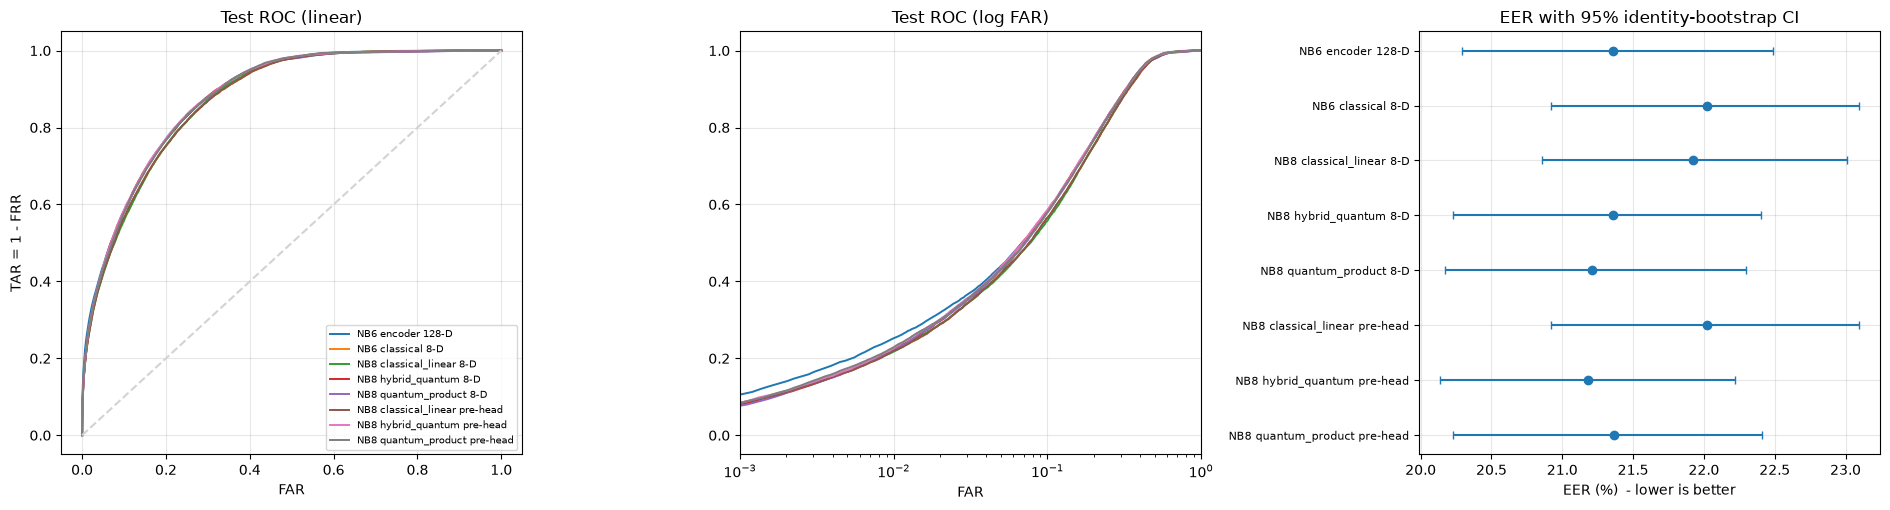

In [10]:
# CELL 10: ROC curves and EER with confidence intervals
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for n, sc in SC.items():
    far, frr = sc.curve()
    ax[0].plot(far, 1 - frr, label=n, lw=1.4)
    ax[1].plot(far, 1 - frr, lw=1.4)
ax[0].plot([0, 1], [0, 1], "--", color="lightgray")
ax[0].set_title("Test ROC (linear)"); ax[0].set_xlabel("FAR"); ax[0].set_ylabel("TAR = 1 - FRR")
ax[1].set_xscale("log"); ax[1].set_xlim(1e-3, 1); ax[1].set_title("Test ROC (log FAR)"); ax[1].set_xlabel("FAR")
ax[0].legend(fontsize=7)
ci = ci_df.set_index("model")
y = np.arange(len(ci))[::-1]
ax[2].errorbar(100 * ci.eer, y, xerr=[100 * (ci.eer - ci.eer_lo), 100 * (ci.eer_hi - ci.eer)], fmt="o", capsize=3)
ax[2].set_yticks(y); ax[2].set_yticklabels(ci.index, fontsize=8)
ax[2].set_xlabel("EER (%)  - lower is better"); ax[2].set_title("EER with 95% identity-bootstrap CI")
for a_ in ax: a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "roc_and_eer.png", dpi=150); plt.show()

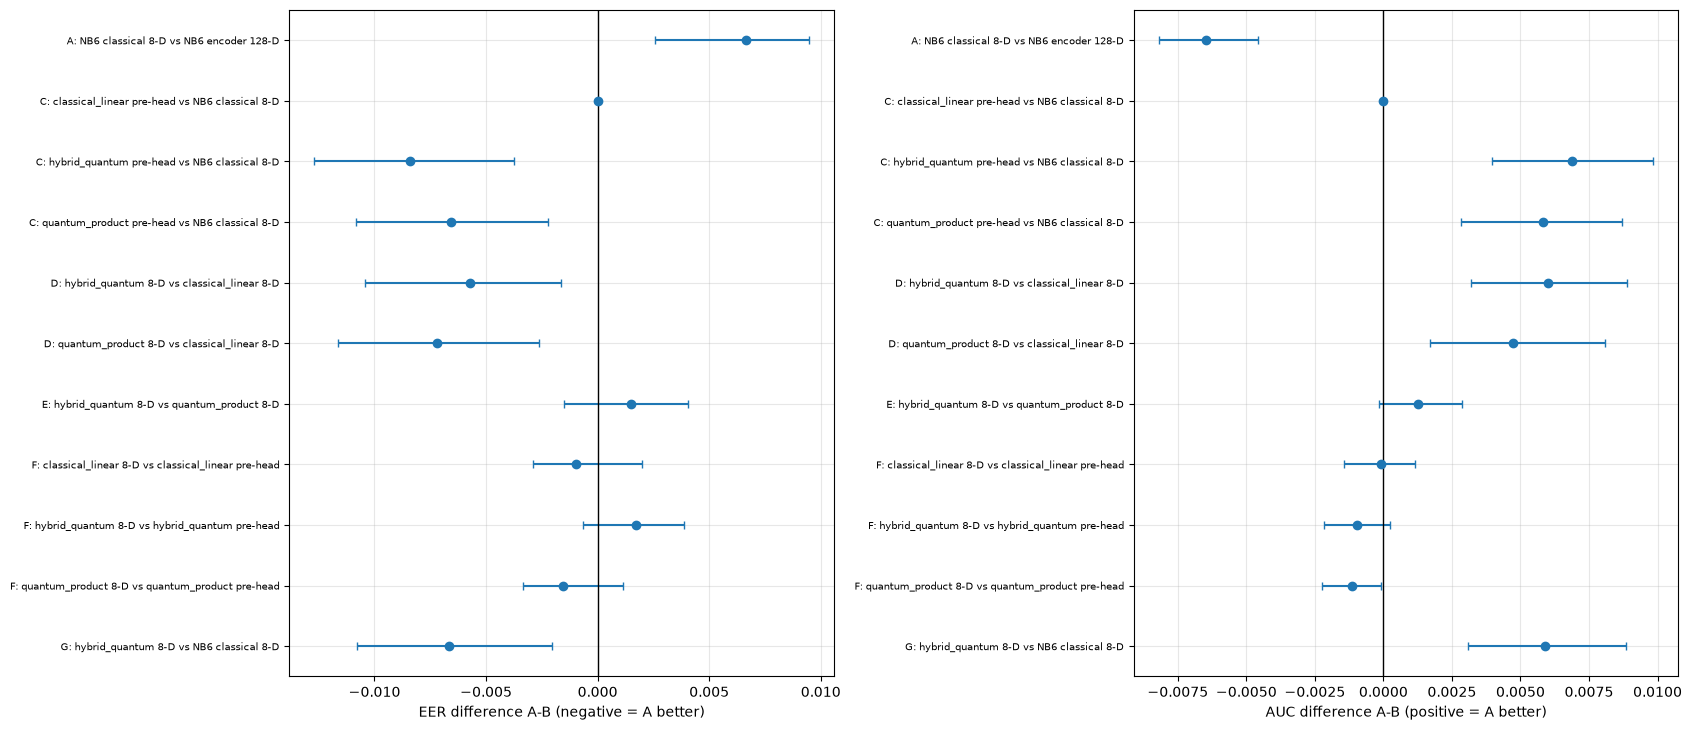

In [11]:
# CELL 11: Ablation forest plot (EER and AUC differences, 95% CI)
fig, ax = plt.subplots(1, 2, figsize=(17, 0.45 * max(len(PAIRS), 6) + 2))
for a_, met, lab in zip(ax, ["eer", "auc"], ["EER difference A-B (negative = A better)", "AUC difference A-B (positive = A better)"]):
    t = ablation_df[ablation_df.metric == met].reset_index(drop=True)
    y = np.arange(len(t))[::-1]
    a_.errorbar(t["A-B"], y, xerr=[t["A-B"] - t.ci_low, t.ci_high - t["A-B"]], fmt="o", capsize=3)
    a_.axvline(0, color="k", lw=1)
    a_.set_yticks(y); a_.set_yticklabels([f"{r.ablation[:1]}: {r.A.replace('NB8 ', '')} vs {r.B.replace('NB8 ', '')}" for _, r in t.iterrows()], fontsize=7)
    a_.set_xlabel(lab); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "ablation_forest.png", dpi=150); plt.show()

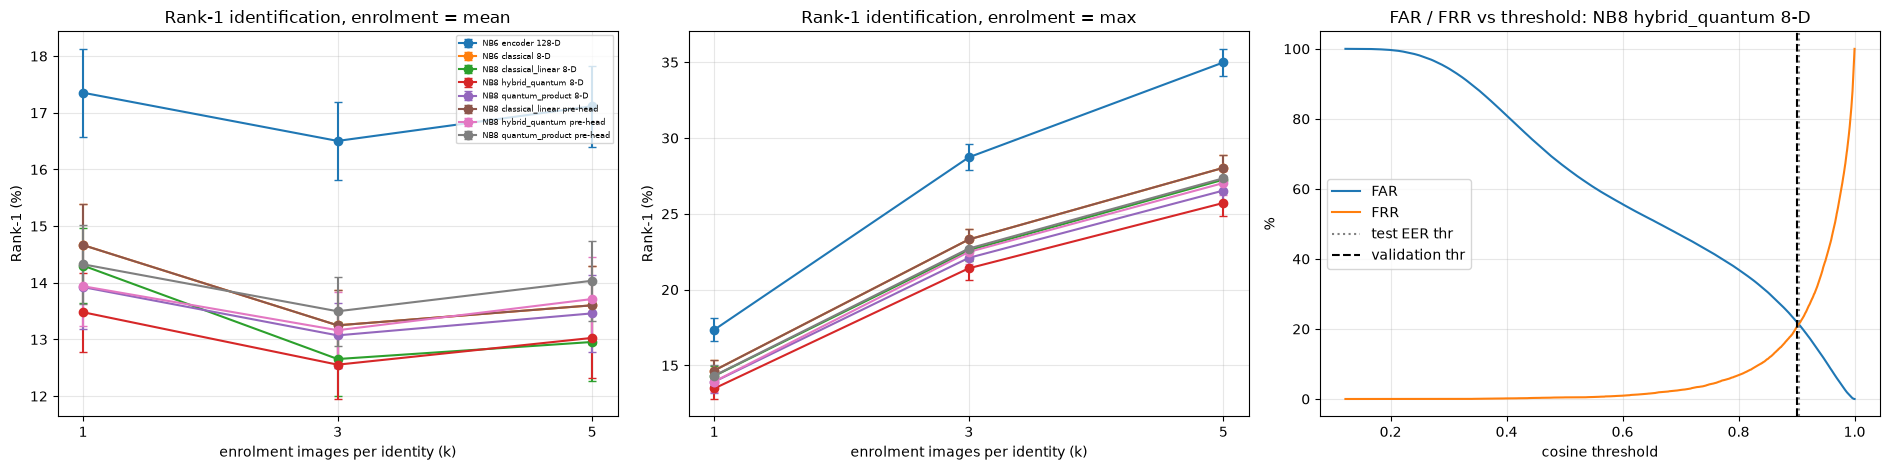

In [12]:
# CELL 12: Rank-1 versus number of shots, and FAR/FRR trade-off of the hybrid model
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for a_, agg in zip(ax[:2], ["mean", "max"]):
    for n in TEST:
        s = rank_df[(rank_df.enroll == agg) & (rank_df.model == n)].sort_values("shots")
        a_.errorbar(s.shots, 100 * s.rank1, yerr=100 * s.rank1_std, marker="o", capsize=3, label=n)
    a_.set_xticks(SHOTS); a_.set_xlabel("enrolment images per identity (k)"); a_.set_ylabel("Rank-1 (%)")
    a_.set_title(f"Rank-1 identification, enrolment = {agg}"); a_.grid(alpha=.3)
ax[0].legend(fontsize=6)
name = "NB8 hybrid_quantum 8-D" if "NB8 hybrid_quantum 8-D" in SC else list(SC)[0]
sc = SC[name]; far, frr = sc.curve()
ax[2].plot(sc.T, 100 * far, label="FAR"); ax[2].plot(sc.T, 100 * frr, label="FRR")
ax[2].axvline(sc.eer_threshold(), color="gray", ls=":", label="test EER thr")
if sc.tv is not None: ax[2].axvline(sc.tv, color="k", ls="--", label="validation thr")
ax[2].set_xlabel("cosine threshold"); ax[2].set_ylabel("%"); ax[2].set_title(f"FAR / FRR vs threshold: {name}")
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "identification_and_far_frr.png", dpi=150); plt.show()

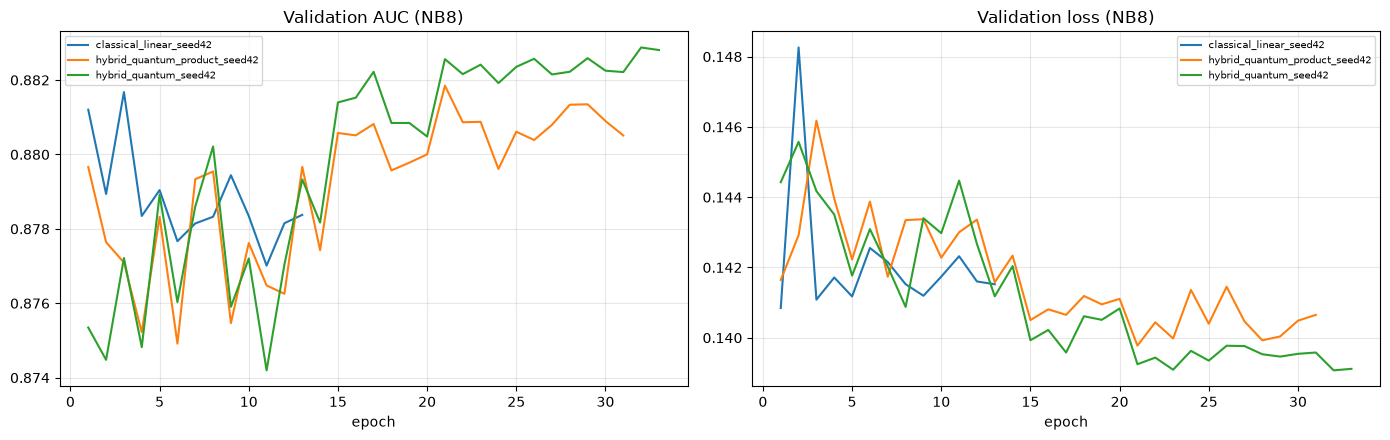

In [13]:
# CELL 13: Training curves from Notebook 8 (skipped if the history files are not there)
hist = sorted(H.glob("history_*_seed*.csv"))
if hist:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for p in hist:
        h = pd.read_csv(p); lab = p.stem.replace("history_", "")
        ax[0].plot(h.epoch, h.validation_auc, label=lab); ax[1].plot(h.epoch, h.validation_loss, label=lab)
    ax[0].set_title("Validation AUC (NB8)"); ax[1].set_title("Validation loss (NB8)")
    for a_ in ax: a_.set_xlabel("epoch"); a_.grid(alpha=.3); a_.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / "nb8_training_curves.png", dpi=150); plt.show()
else:
    print("No NB8 history files found in", H)

In [14]:
# CELL 14: Cross-check with the numbers each earlier notebook reported (its own fixed test pairs)
rows = []
def add(label, path, pick):
    if path.exists():
        for r in pick(pd.read_csv(path)): rows.append({"source": label, **r})
    else:
        print("not found:", path)

add("NB5", N5 / "final_results.csv", lambda d: [{"model": "Siamese 128-D", "test_auc": d.test_auc.iloc[0], "test_eer": d.test_eer.iloc[0], "test_accuracy": d.test_accuracy.iloc[0]}])
add("NB6", N6 / "final_results.csv", lambda d: [{"model": "classical projection 8-D", "test_auc": d.test_auc.iloc[0], "test_eer": d.test_eer.iloc[0], "test_accuracy": d.test_accuracy.iloc[0]}])
add("NB7", N7 / "final_comparison.csv", lambda d: [{"model": r.model + " (frozen features)", "test_auc": r.test_auc_mean, "test_eer": r.test_eer_mean, "test_accuracy": r.test_accuracy_mean} for r in d.itertuples()])
add("NB8", H / "final_results.csv", lambda d: [{"model": r.variant, "test_auc": r.test_auc, "test_eer": r.test_eer, "test_accuracy": r.test_accuracy, "head_parameters": r.head_parameters} for r in d.itertuples()])
reported_df = pd.DataFrame(rows)
if len(reported_df):
    reported_df.to_csv(OUT / "reported_by_notebooks.csv", index=False)
    print(reported_df.round(4).to_string(index=False))
    print("\nThese use each notebook's own 5,000 test pairs; Part 1 uses all genuine pairs plus a shared impostor sample.")
    print("Absolute values differ a little; the ORDER of the models should agree. Notebook 4 (softmax CNN) is a closed-set")
    print("classifier with no verification score, so it is not part of this table.")

source                              model  test_auc  test_eer  test_accuracy  head_parameters
   NB5                      Siamese 128-D    0.8797    0.2192         0.7928              NaN
   NB6           classical projection 8-D    0.8747    0.2218         0.7858              NaN
   NB7      Raw NB6 8-D (frozen features)    0.8747    0.2218         0.7858              NaN
   NB7 Classical linear (frozen features)    0.8765    0.2167         0.7899              NaN
   NB7    Classical MLP (frozen features)    0.8769    0.2168         0.7912              NaN
   NB7      Quantum VQC (frozen features)    0.8755    0.2181         0.7868              NaN
   NB8              reference_nb6 (start)    0.8747    0.2218         0.7858              0.0
   NB8                     hybrid_quantum    0.8813    0.2138         0.7990             48.0
   NB8                   classical_linear    0.8761    0.2158         0.7872             64.0
   NB8             hybrid_quantum_product    0.8803    0.209

In [15]:
# CELL 15: Written summary generated from the results above
def row(grp, a, b, met):
    t = ablation_df[(ablation_df.ablation == grp) & (ablation_df.A == a) & (ablation_df.B == b) & (ablation_df.metric == met)]
    return None if t.empty else t.iloc[0]

lines = []
best = ci_df.sort_values("eer").iloc[0]
lines.append(f"Lowest test EER: {best.model} ({100*best.eer:.2f}%, 95% CI {100*best.eer_lo:.2f}-{100*best.eer_hi:.2f}%).")
for grp, a, b in PAIRS:
    r = row(grp, a, b, "eer")
    if r is not None:
        lines.append(f"[{grp}] {a} vs {b}: EER diff {100*r['A-B']:+.2f} pts "
                     f"(CI {100*r.ci_low:+.2f} to {100*r.ci_high:+.2f}) -> {r.verdict}.")
qv = row("D head type (quantum vs linear)", "NB8 hybrid_quantum 8-D", "NB8 classical_linear 8-D", "eer")
if qv is not None:
    lines.append("")
    lines.append("Quantum vs classical head: " + (
        "the interval excludes 0 on EER, but this is ONE training seed. Confirm with several seeds before claiming a quantum benefit."
        if qv.verdict != "no clear difference" else
        "no clear difference on EER; the circuit is at best on par with the classical head."))
en = row("E entanglement", "NB8 hybrid_quantum 8-D", "NB8 quantum_product 8-D", "eer")
if en is not None:
    lines.append("Entanglement: " + ("no measurable contribution." if en.verdict == "no clear difference" else f"{en.verdict} on EER."))
lines += ["", "Caveats: single training seed per variant; intervals cover test-identity sampling only;",
          f"{len(PAIRS)} ablation pairs examined, so isolated borderline results should be read with care."]
summary = "\n".join(lines)
(OUT / "summary.txt").write_text(summary)
print(summary)

Lowest test EER: NB8 hybrid_quantum pre-head (21.18%, 95% CI 20.14-22.22%).
[A bottleneck 128-D -> 8-D] NB6 classical 8-D vs NB6 encoder 128-D: EER diff +0.66 pts (CI +0.26 to +0.95) -> B better.
[C joint fine-tuning (no head)] NB8 classical_linear pre-head vs NB6 classical 8-D: EER diff +0.00 pts (CI +0.00 to +0.00) -> no clear difference.
[C joint fine-tuning (no head)] NB8 hybrid_quantum pre-head vs NB6 classical 8-D: EER diff -0.84 pts (CI -1.27 to -0.37) -> A better.
[C joint fine-tuning (no head)] NB8 quantum_product pre-head vs NB6 classical 8-D: EER diff -0.66 pts (CI -1.08 to -0.22) -> A better.
[D head type (quantum vs linear)] NB8 hybrid_quantum 8-D vs NB8 classical_linear 8-D: EER diff -0.57 pts (CI -1.04 to -0.16) -> A better.
[D head type (quantum vs linear)] NB8 quantum_product 8-D vs NB8 classical_linear 8-D: EER diff -0.72 pts (CI -1.16 to -0.26) -> A better.
[E entanglement] NB8 hybrid_quantum 8-D vs NB8 quantum_product 8-D: EER diff +0.15 pts (CI -0.15 to +0.40) -> n

In [16]:
# CELL 16: Save configuration and finish
with open(OUT / "ablation_config.json", "w") as f:
    json.dump({"suffix": SUFFIX, "seed": SEED, "n_impostor": N_IMPOSTOR, "n_boot": N_BOOT, "shots": SHOTS,
               "episodes": N_EPISODES, "models": list(TEST), "pairs": PAIRS,
               "n_test_identities": int(len(cls_t))}, f, indent=2)
print("=" * 60); print("NOTEBOOK 10 COMPLETED"); print("=" * 60)
for p in sorted(OUT.iterdir()): print(" -", p.name)

NOTEBOOK 10 COMPLETED
 - ablation_config.json
 - ablation_forest.png
 - ablation_paired_bootstrap.csv
 - bootstrap_intervals.csv
 - identification_and_far_frr.png
 - identification_episodes.csv
 - identification_paired.csv
 - identification_summary.csv
 - nb8_training_curves.png
 - reported_by_notebooks.csv
 - roc_and_eer.png
 - summary.txt
 - verification_results.csv


## How to read the outcome

| Result | Meaning |
|---|---|
| D and G: CI excludes 0 in favour of the quantum head, repeated over several training seeds | A real, if small, benefit from the circuit - report effect size with its CI |
| D: no clear difference, F shows both heads add ~nothing over their trunk | The gain comes from joint fine-tuning (ablation C), not from the head |
| E: no clear difference | Entanglement does not contribute on this task |
| A: large loss going from 128-D to 8-D | The bottleneck, not the head, limits performance; the next lever is more qubits / a larger projection |

Any of these is a valid, publishable conclusion. The honest claim is whatever the intervals support.

## Next steps (optional)

- Re-run Notebook 8 with two or three more `SEED` values and add the embeddings here to include training-seed variance.
- Add Notebook 5 embeddings (`test_embeddings.npz` with an `embeddings` key) so ablation B is not skipped.